In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

In [2]:
def u0(x):
    return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

t_min = 0
t_max = 1
x_min = -1
x_max = 1

In [3]:
import jax.numpy as jnp
from jax import vmap
import numpy as np

# The PiecewiseLinearPolynomials class definition here (copy from previous messages)

def test_quadrature():
    # Parameters for the domain [0, 0.5] x [-1, 1] x [0, 2]
    N_t = 10  # Divisions in t
    N_x = 5  # Divisions in x
    N_y = 2  # Divisions in y
    t_min = 0.0
    t_max = 1.5
    x_min = -1.0
    x_max = 1.0
    y_min = 0.0
    y_max = 2.0
    gauss_order = 5  # For accurate quadrature

    # Instantiate the class
    pwp = PiecewiseLinearPolynomialsHex(
        N_t=N_t, N_x=N_x, N_y=N_y,
        t_min=t_min, t_max=t_max,
        x_min=x_min, x_max=x_max,
        y_min=y_min, y_max=y_max,
        gauss_order=gauss_order
    )

    # Define the function f(t, x, y) = sin(t) * x^2 + sin(t) * y^3
    def f(txy):
        t, x, y = txy
        return jnp.sin(t) * x**2 + jnp.sin(t) * y**3

    # Vectorized function evaluation
    f_vec = vmap(f)(pwp.quad_points)
    # Numerical integral = sum(f * weights)
    numerical_integral = jnp.sum(f_vec * pwp.quad_weights)

    # Analytical integral
    # ∫_0^t_max sin(t) dt = 1 - cos(t_max)
    int_sin_t = 1 - jnp.cos(t_max)
    # ∫_{-1}^1 ∫_0^2 x^2 dy dx = 2 * ∫_{-1}^1 x^2 dx = 2 * (2/3) = 4/3
    int_x2 = 4 / 3
    # ∫_{-1}^1 ∫_0^2 y^3 dy dx = ∫_{-1}^1 4 dx = 8
    int_y3 = 8
    analytical_integral = int_sin_t * (int_x2 + int_y3)

    print("Numerical Integral:", numerical_integral)
    print("Analytical Integral:", analytical_integral)
    print("Absolute Error:", jnp.abs(numerical_integral - analytical_integral))

# Run the test
test_quadrature()

Numerical Integral: 8.673119
Analytical Integral: 8.67312
Absolute Error: 9.536743e-07


In [7]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1.5
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0
gauss_order = 3  # For accurate quadrature

# Instantiate the class
pwp = PiecewiseLinearPolynomialsHex(
    N_t=N_t, N_x=N_x, N_y=N_y,
    t_min=t_min, t_max=t_max,
    x_min=x_min, x_max=x_max,
    y_min=y_min, y_max=y_max,
    gauss_order=gauss_order
)
parti_idx = 0
quad_points = pwp.quad_points_parti[parti_idx]
quad_weights = pwp.quad_weights_parti[parti_idx]
print(quad_weights)

[0.00128601 0.00205761 0.00128601 0.00205761 0.00329218 0.00205761
 0.00128601 0.00205761 0.00128601 0.00205761 0.00329218 0.00205761
 0.00329218 0.00526749 0.00329218 0.00205761 0.00329218 0.00205761
 0.00128601 0.00205761 0.00128601 0.00205761 0.00329218 0.00205761
 0.00128601 0.00205761 0.00128601]


In [2]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

def res_visc(u_quad, u_t, u_x, u_y, u_xx, nu):
    return u_t + u_quad * u_x + u_quad * u_y - nu*u_xx

N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[20000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex',
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Plotting before training segment [0.0000, 0.5000]


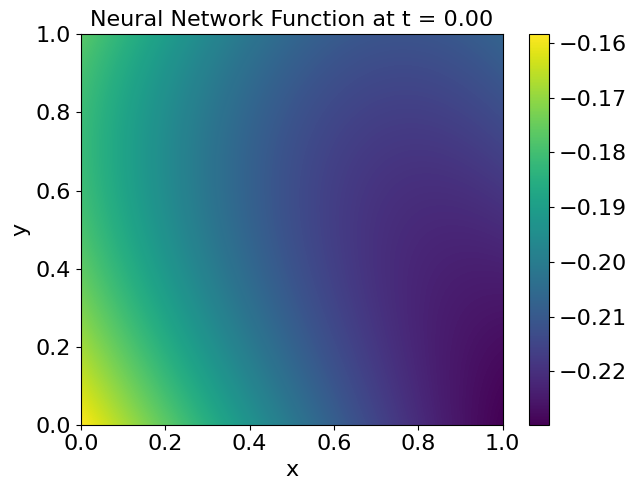

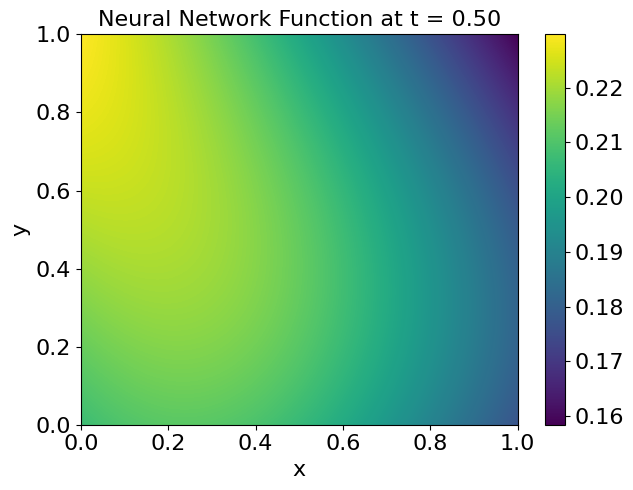


Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.737366, lambda_bc: 18.314133, lambda_eqn: 1.083135
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410650, loss_l1: 0.410650, loss_ibc: 2.622107


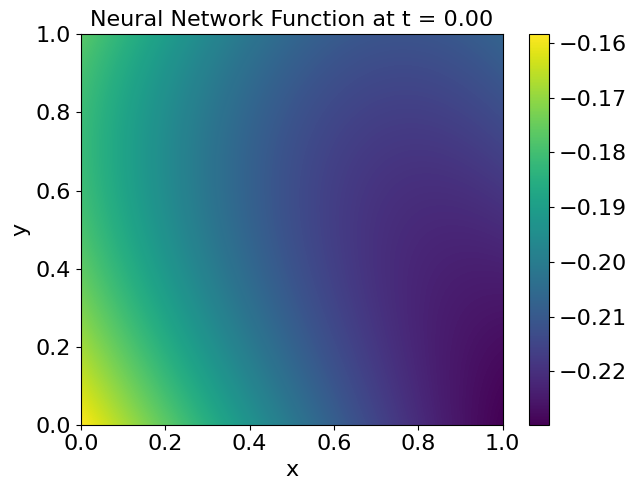

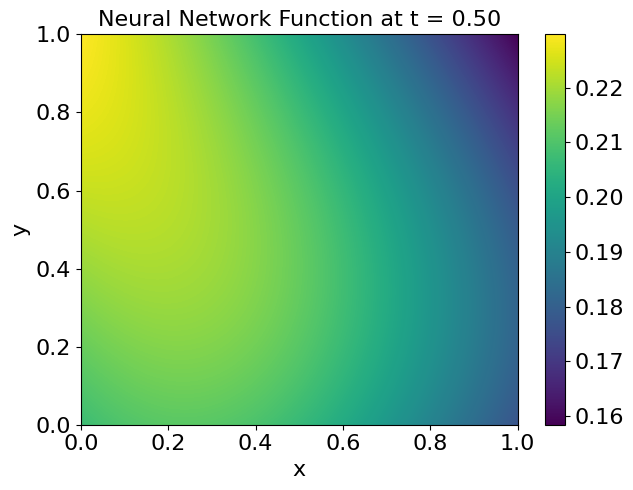

Grade 0, Iter 100, loss_eqn: 0.409069, loss_eqn_from_kh: 0.408426, loss_l1: 0.408427, loss_ibc: 0.713444
Grade 0, Iter 200, loss_eqn: 0.346405, loss_eqn_from_kh: 0.346228, loss_l1: 0.346228, loss_ibc: 0.605119
Grade 0, Iter 300, loss_eqn: 0.375658, loss_eqn_from_kh: 0.375787, loss_l1: 0.375789, loss_ibc: 0.417891
Grade 0, Iter 400, loss_eqn: 0.330425, loss_eqn_from_kh: 0.330841, loss_l1: 0.330844, loss_ibc: 0.253195
Grade 0, Iter 500, loss_eqn: 0.389084, loss_eqn_from_kh: 0.388301, loss_l1: 0.412761, loss_ibc: 0.144392
Grade 0, Iter 600, loss_eqn: 0.335173, loss_eqn_from_kh: 0.333601, loss_l1: 0.405542, loss_ibc: 0.107014
Grade 0, Iter 700, loss_eqn: 0.289920, loss_eqn_from_kh: 0.289761, loss_l1: 0.411007, loss_ibc: 0.086118
Grade 0, Iter 800, loss_eqn: 0.259424, loss_eqn_from_kh: 0.259582, loss_l1: 0.392235, loss_ibc: 0.070624
Grade 0, Iter 900, loss_eqn: 0.251331, loss_eqn_from_kh: 0.251542, loss_l1: 0.370067, loss_ibc: 0.058918
Grade 0, Iter 1000, loss_eqn: 0.240665, loss_eqn_from_k

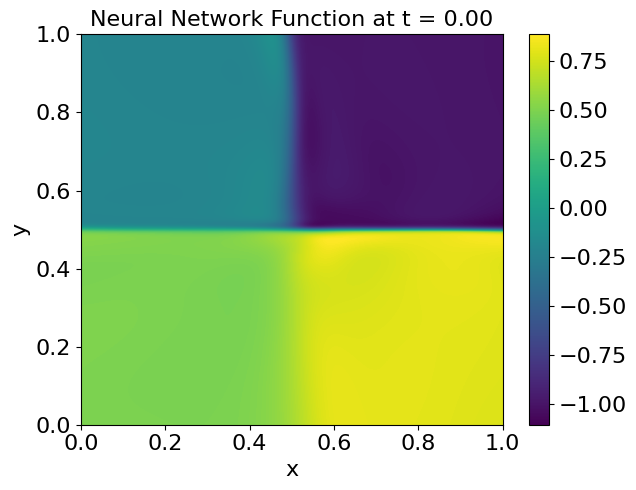

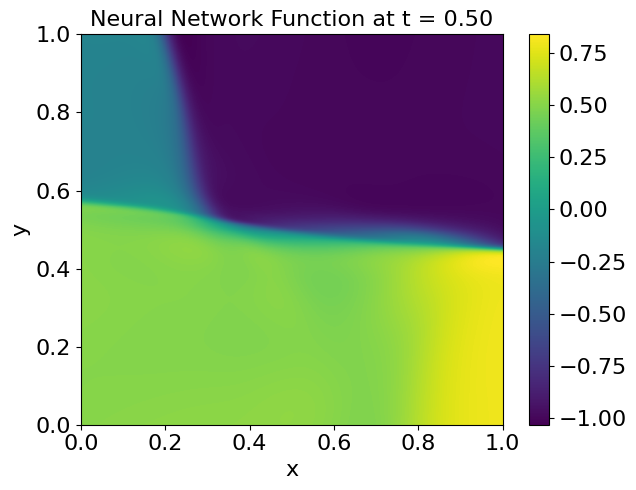

Grade 0, Iter 2100, loss_eqn: 0.128046, loss_eqn_from_kh: 0.125034, loss_l1: 0.263295, loss_ibc: 0.010772
Grade 0, Iter 2200, loss_eqn: 0.119951, loss_eqn_from_kh: 0.118337, loss_l1: 0.265455, loss_ibc: 0.009645
Grade 0, Iter 2300, loss_eqn: 0.110295, loss_eqn_from_kh: 0.110636, loss_l1: 0.267121, loss_ibc: 0.008581
Grade 0, Iter 2400, loss_eqn: 0.104784, loss_eqn_from_kh: 0.104233, loss_l1: 0.269698, loss_ibc: 0.007780
Grade 0, Iter 2500, loss_eqn: 0.098339, loss_eqn_from_kh: 0.098463, loss_l1: 0.269457, loss_ibc: 0.007086
Grade 0, Iter 2600, loss_eqn: 0.090858, loss_eqn_from_kh: 0.088242, loss_l1: 0.266674, loss_ibc: 0.006437
Grade 0, Iter 2700, loss_eqn: 0.084559, loss_eqn_from_kh: 0.083644, loss_l1: 0.263437, loss_ibc: 0.005952
Grade 0, Iter 2800, loss_eqn: 0.079976, loss_eqn_from_kh: 0.079661, loss_l1: 0.257775, loss_ibc: 0.005477
Grade 0, Iter 2900, loss_eqn: 0.076709, loss_eqn_from_kh: 0.074781, loss_l1: 0.257419, loss_ibc: 0.005181
Grade 0, Iter 3000, loss_eqn: 0.071358, loss_e

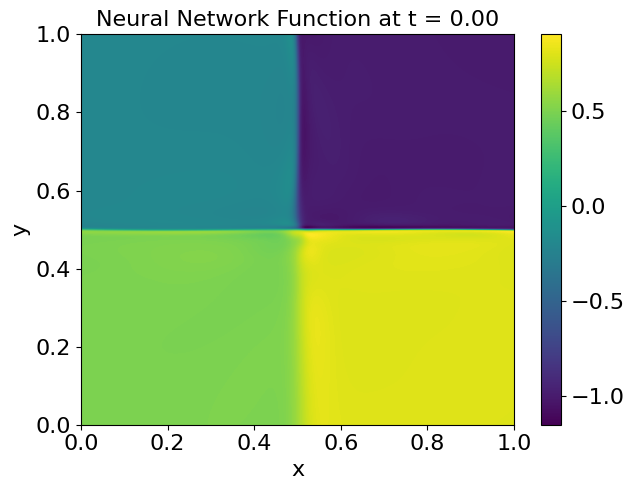

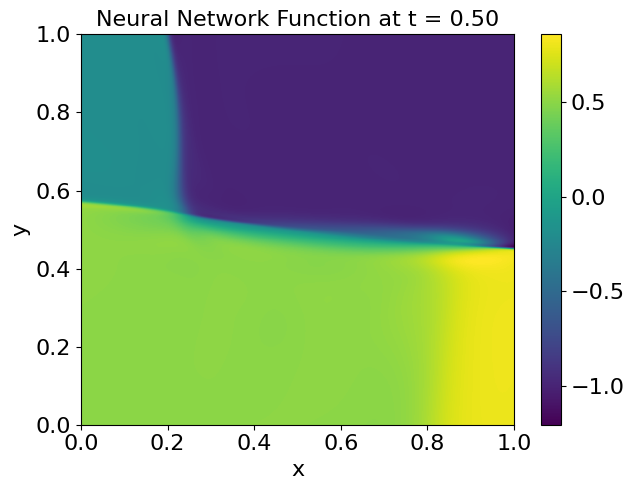

Grade 0, Iter 4100, loss_eqn: 0.050092, loss_eqn_from_kh: 0.047778, loss_l1: 0.258607, loss_ibc: 0.003111
Grade 0, Iter 4200, loss_eqn: 0.049876, loss_eqn_from_kh: 0.048372, loss_l1: 0.258949, loss_ibc: 0.002949
Grade 0, Iter 4300, loss_eqn: 0.048036, loss_eqn_from_kh: 0.045846, loss_l1: 0.261294, loss_ibc: 0.002802
Grade 0, Iter 4400, loss_eqn: 0.047804, loss_eqn_from_kh: 0.045410, loss_l1: 0.259838, loss_ibc: 0.002711
Grade 0, Iter 4500, loss_eqn: 0.045996, loss_eqn_from_kh: 0.044316, loss_l1: 0.259331, loss_ibc: 0.002681
Grade 0, Iter 4600, loss_eqn: 0.046757, loss_eqn_from_kh: 0.043512, loss_l1: 0.258809, loss_ibc: 0.002649
Grade 0, Iter 4700, loss_eqn: 0.042573, loss_eqn_from_kh: 0.045077, loss_l1: 0.259837, loss_ibc: 0.002441
Grade 0, Iter 4800, loss_eqn: 0.049394, loss_eqn_from_kh: 0.044130, loss_l1: 0.255025, loss_ibc: 0.002542
Grade 0, Iter 4900, loss_eqn: 0.044408, loss_eqn_from_kh: 0.041797, loss_l1: 0.254458, loss_ibc: 0.002380
Grade 0, Iter 5000, loss_eqn: 0.043077, loss_e

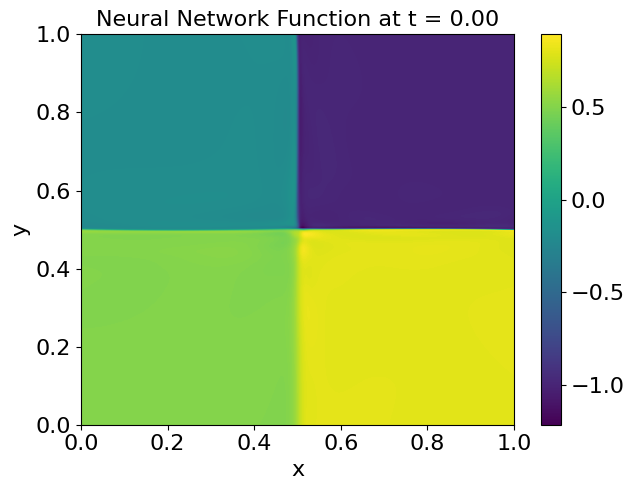

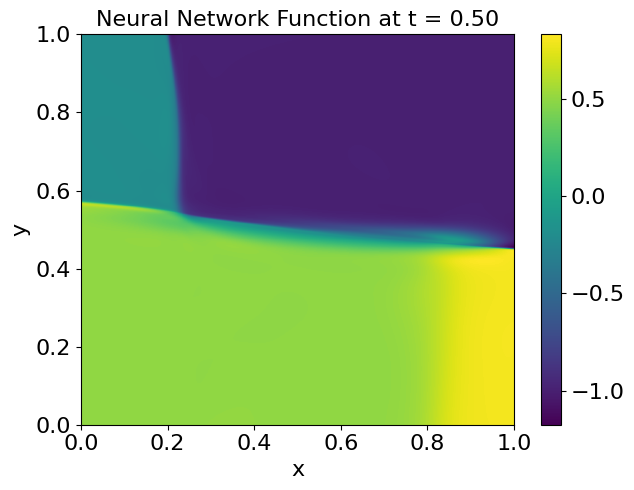

Grade 0, Iter 6100, loss_eqn: 0.033331, loss_eqn_from_kh: 0.032849, loss_l1: 0.249488, loss_ibc: 0.001780
Grade 0, Iter 6200, loss_eqn: 0.037984, loss_eqn_from_kh: 0.035824, loss_l1: 0.248686, loss_ibc: 0.001706
Grade 0, Iter 6300, loss_eqn: 0.032607, loss_eqn_from_kh: 0.032262, loss_l1: 0.245318, loss_ibc: 0.001695
Grade 0, Iter 6400, loss_eqn: 0.034512, loss_eqn_from_kh: 0.035118, loss_l1: 0.246305, loss_ibc: 0.001657
Grade 0, Iter 6500, loss_eqn: 0.034389, loss_eqn_from_kh: 0.034392, loss_l1: 0.243961, loss_ibc: 0.001645
Grade 0, Iter 6600, loss_eqn: 0.036305, loss_eqn_from_kh: 0.034954, loss_l1: 0.246910, loss_ibc: 0.001540
Grade 0, Iter 6700, loss_eqn: 0.034190, loss_eqn_from_kh: 0.031781, loss_l1: 0.243122, loss_ibc: 0.001498
Grade 0, Iter 6800, loss_eqn: 0.032487, loss_eqn_from_kh: 0.030911, loss_l1: 0.241291, loss_ibc: 0.001529
Grade 0, Iter 6900, loss_eqn: 0.029929, loss_eqn_from_kh: 0.030855, loss_l1: 0.241867, loss_ibc: 0.001457
Grade 0, Iter 7000, loss_eqn: 0.036224, loss_e

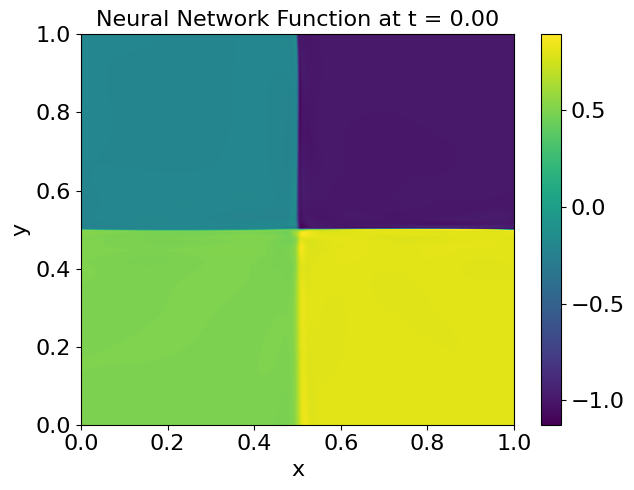

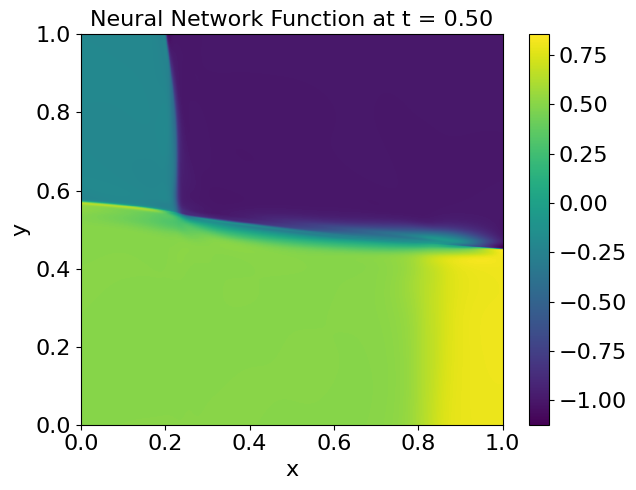

Grade 0, Iter 8100, loss_eqn: 0.028360, loss_eqn_from_kh: 0.027304, loss_l1: 0.232825, loss_ibc: 0.001198
Grade 0, Iter 8200, loss_eqn: 0.029136, loss_eqn_from_kh: 0.026633, loss_l1: 0.235718, loss_ibc: 0.001211
Grade 0, Iter 8300, loss_eqn: 0.026705, loss_eqn_from_kh: 0.028166, loss_l1: 0.232533, loss_ibc: 0.001152
Grade 0, Iter 8400, loss_eqn: 0.025318, loss_eqn_from_kh: 0.028089, loss_l1: 0.234874, loss_ibc: 0.001107
Grade 0, Iter 8500, loss_eqn: 0.027471, loss_eqn_from_kh: 0.026844, loss_l1: 0.233401, loss_ibc: 0.001093
Grade 0, Iter 8600, loss_eqn: 0.026776, loss_eqn_from_kh: 0.025697, loss_l1: 0.229527, loss_ibc: 0.001093
Grade 0, Iter 8700, loss_eqn: 0.025285, loss_eqn_from_kh: 0.026099, loss_l1: 0.229204, loss_ibc: 0.001067
Grade 0, Iter 8800, loss_eqn: 0.025847, loss_eqn_from_kh: 0.027041, loss_l1: 0.231478, loss_ibc: 0.001060
Grade 0, Iter 8900, loss_eqn: 0.025409, loss_eqn_from_kh: 0.024397, loss_l1: 0.230470, loss_ibc: 0.001059
Grade 0, Iter 9000, loss_eqn: 0.026831, loss_e

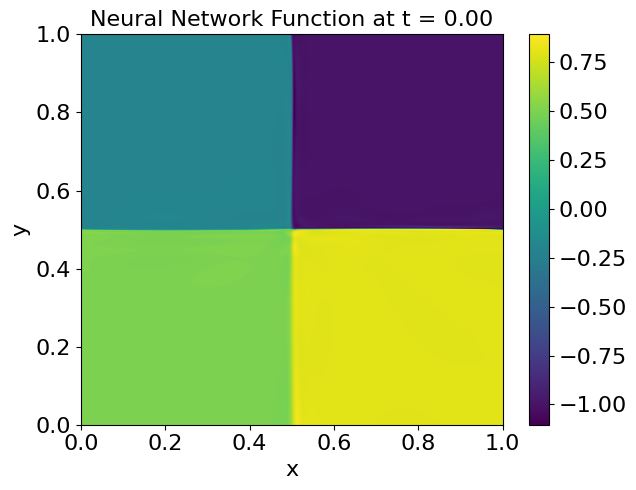

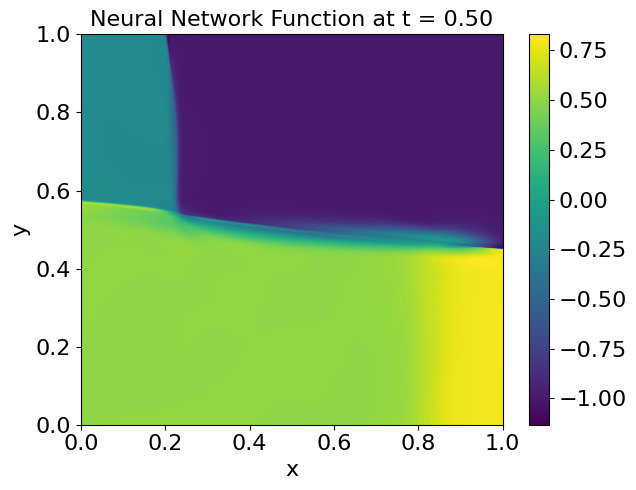

Grade 0, Iter 10100, loss_eqn: 0.022353, loss_eqn_from_kh: 0.022294, loss_l1: 0.224368, loss_ibc: 0.000891
Grade 0, Iter 10200, loss_eqn: 0.021285, loss_eqn_from_kh: 0.021816, loss_l1: 0.223140, loss_ibc: 0.000881
Grade 0, Iter 10300, loss_eqn: 0.022150, loss_eqn_from_kh: 0.022008, loss_l1: 0.222079, loss_ibc: 0.000879
Grade 0, Iter 10400, loss_eqn: 0.021474, loss_eqn_from_kh: 0.022920, loss_l1: 0.222240, loss_ibc: 0.000859
Grade 0, Iter 10500, loss_eqn: 0.020717, loss_eqn_from_kh: 0.022045, loss_l1: 0.222806, loss_ibc: 0.000838
Grade 0, Iter 10600, loss_eqn: 0.020731, loss_eqn_from_kh: 0.021442, loss_l1: 0.221448, loss_ibc: 0.000834
Grade 0, Iter 10700, loss_eqn: 0.020410, loss_eqn_from_kh: 0.021609, loss_l1: 0.220359, loss_ibc: 0.000820
Grade 0, Iter 10800, loss_eqn: 0.019515, loss_eqn_from_kh: 0.020187, loss_l1: 0.221074, loss_ibc: 0.000825
Grade 0, Iter 10900, loss_eqn: 0.019888, loss_eqn_from_kh: 0.020101, loss_l1: 0.220437, loss_ibc: 0.000811
Grade 0, Iter 11000, loss_eqn: 0.0199

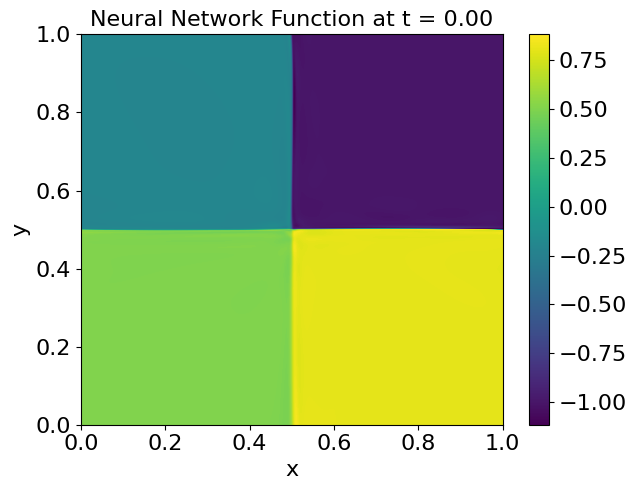

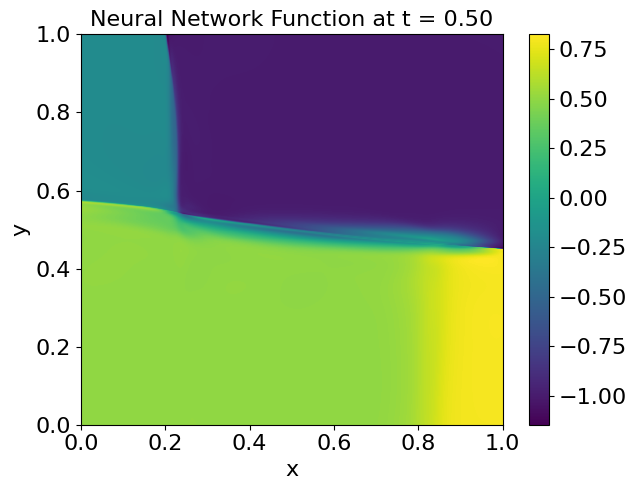

Grade 0, Iter 12100, loss_eqn: 0.017592, loss_eqn_from_kh: 0.018026, loss_l1: 0.215867, loss_ibc: 0.000721
Grade 0, Iter 12200, loss_eqn: 0.018251, loss_eqn_from_kh: 0.018640, loss_l1: 0.215666, loss_ibc: 0.000708
Grade 0, Iter 12300, loss_eqn: 0.019365, loss_eqn_from_kh: 0.017961, loss_l1: 0.215642, loss_ibc: 0.000710
Grade 0, Iter 12400, loss_eqn: 0.017835, loss_eqn_from_kh: 0.017168, loss_l1: 0.214149, loss_ibc: 0.000696
Grade 0, Iter 12500, loss_eqn: 0.017886, loss_eqn_from_kh: 0.016572, loss_l1: 0.214491, loss_ibc: 0.000684
Grade 0, Iter 12600, loss_eqn: 0.017408, loss_eqn_from_kh: 0.016586, loss_l1: 0.212956, loss_ibc: 0.000674
Grade 0, Iter 12700, loss_eqn: 0.017879, loss_eqn_from_kh: 0.017651, loss_l1: 0.214276, loss_ibc: 0.000678
Grade 0, Iter 12800, loss_eqn: 0.017938, loss_eqn_from_kh: 0.017324, loss_l1: 0.214387, loss_ibc: 0.000692
Grade 0, Iter 12900, loss_eqn: 0.016592, loss_eqn_from_kh: 0.017393, loss_l1: 0.214630, loss_ibc: 0.000660
Grade 0, Iter 13000, loss_eqn: 0.0173

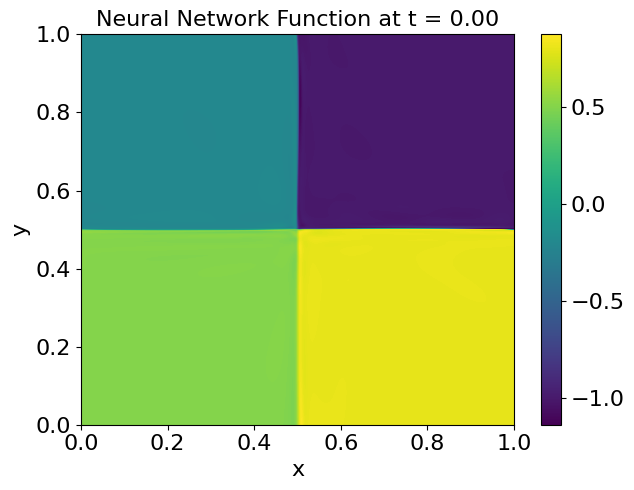

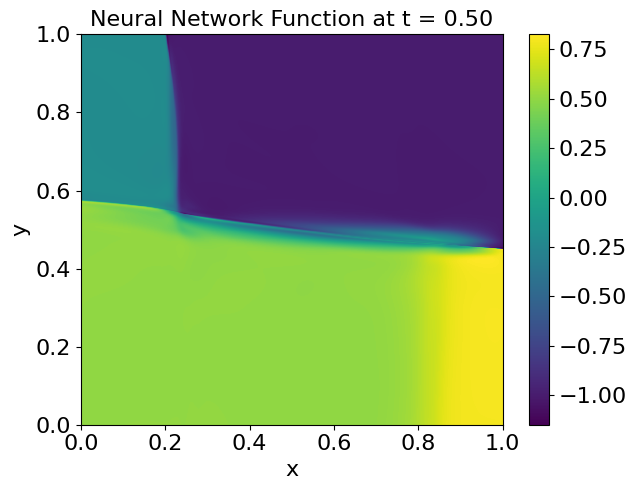

Grade 0, Iter 14100, loss_eqn: 0.015440, loss_eqn_from_kh: 0.015975, loss_l1: 0.211523, loss_ibc: 0.000607
Grade 0, Iter 14200, loss_eqn: 0.014126, loss_eqn_from_kh: 0.015570, loss_l1: 0.211080, loss_ibc: 0.000589
Grade 0, Iter 14300, loss_eqn: 0.015304, loss_eqn_from_kh: 0.015171, loss_l1: 0.210807, loss_ibc: 0.000586
Grade 0, Iter 14400, loss_eqn: 0.016415, loss_eqn_from_kh: 0.015972, loss_l1: 0.210545, loss_ibc: 0.000582
Grade 0, Iter 14500, loss_eqn: 0.016113, loss_eqn_from_kh: 0.014497, loss_l1: 0.209803, loss_ibc: 0.000579
Grade 0, Iter 14600, loss_eqn: 0.015724, loss_eqn_from_kh: 0.013848, loss_l1: 0.210071, loss_ibc: 0.000569
Grade 0, Iter 14700, loss_eqn: 0.015001, loss_eqn_from_kh: 0.014408, loss_l1: 0.210503, loss_ibc: 0.000575
Grade 0, Iter 14800, loss_eqn: 0.016054, loss_eqn_from_kh: 0.015778, loss_l1: 0.210201, loss_ibc: 0.000565
Grade 0, Iter 14900, loss_eqn: 0.014696, loss_eqn_from_kh: 0.015119, loss_l1: 0.210901, loss_ibc: 0.000567
Grade 0, Iter 15000, loss_eqn: 0.0139

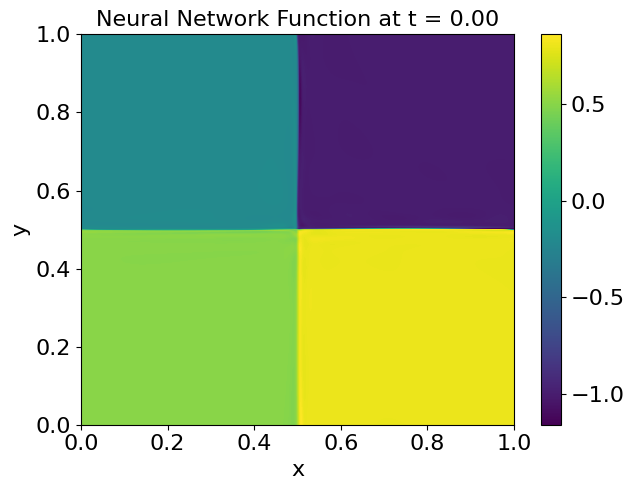

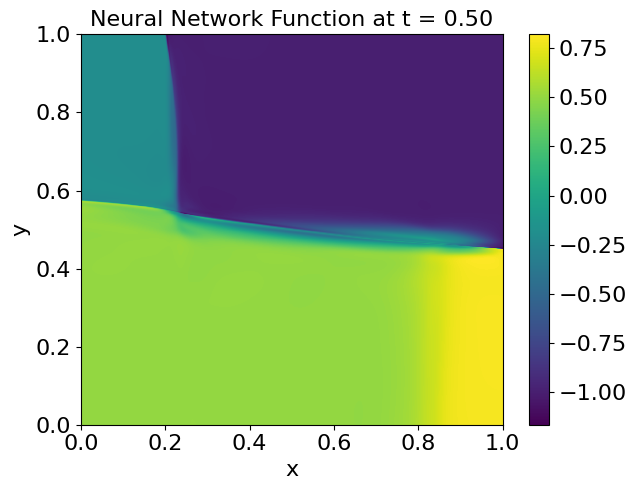

Grade 0, Iter 16100, loss_eqn: 0.013028, loss_eqn_from_kh: 0.013326, loss_l1: 0.207662, loss_ibc: 0.000524
Grade 0, Iter 16200, loss_eqn: 0.013211, loss_eqn_from_kh: 0.013477, loss_l1: 0.207644, loss_ibc: 0.000525
Grade 0, Iter 16300, loss_eqn: 0.013480, loss_eqn_from_kh: 0.013595, loss_l1: 0.208270, loss_ibc: 0.000518
Grade 0, Iter 16400, loss_eqn: 0.012948, loss_eqn_from_kh: 0.012706, loss_l1: 0.207208, loss_ibc: 0.000516
Grade 0, Iter 16500, loss_eqn: 0.012763, loss_eqn_from_kh: 0.012845, loss_l1: 0.206657, loss_ibc: 0.000512
Grade 0, Iter 16600, loss_eqn: 0.013204, loss_eqn_from_kh: 0.013286, loss_l1: 0.207259, loss_ibc: 0.000512
Grade 0, Iter 16700, loss_eqn: 0.012674, loss_eqn_from_kh: 0.012504, loss_l1: 0.206853, loss_ibc: 0.000509
Grade 0, Iter 16800, loss_eqn: 0.012676, loss_eqn_from_kh: 0.012765, loss_l1: 0.207058, loss_ibc: 0.000508
Grade 0, Iter 16900, loss_eqn: 0.012571, loss_eqn_from_kh: 0.012632, loss_l1: 0.206798, loss_ibc: 0.000509
Grade 0, Iter 17000, loss_eqn: 0.0127

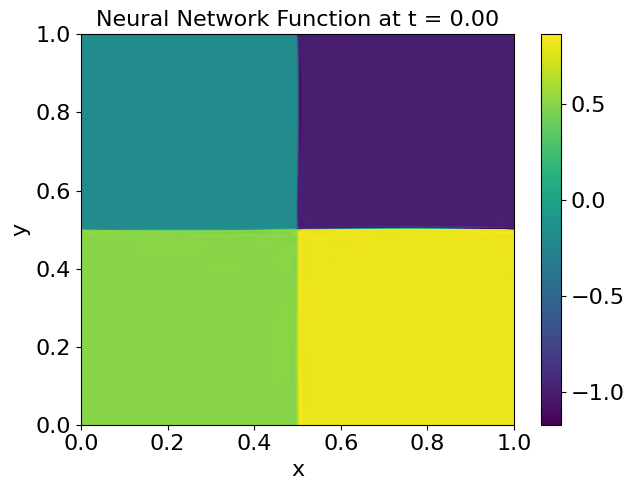

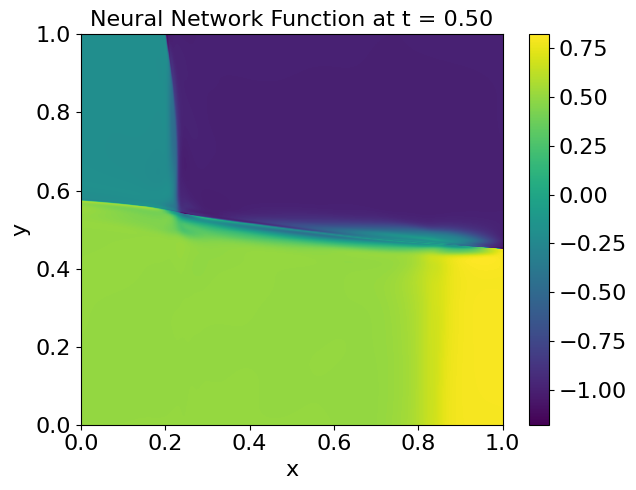

Grade 0, Iter 18100, loss_eqn: 0.012148, loss_eqn_from_kh: 0.012187, loss_l1: 0.205739, loss_ibc: 0.000483
Grade 0, Iter 18200, loss_eqn: 0.012438, loss_eqn_from_kh: 0.012760, loss_l1: 0.205983, loss_ibc: 0.000480
Grade 0, Iter 18300, loss_eqn: 0.012519, loss_eqn_from_kh: 0.012288, loss_l1: 0.206055, loss_ibc: 0.000476
Grade 0, Iter 18400, loss_eqn: 0.012427, loss_eqn_from_kh: 0.012943, loss_l1: 0.206519, loss_ibc: 0.000473
Grade 0, Iter 18500, loss_eqn: 0.012609, loss_eqn_from_kh: 0.012682, loss_l1: 0.206272, loss_ibc: 0.000470
Grade 0, Iter 18600, loss_eqn: 0.012936, loss_eqn_from_kh: 0.012501, loss_l1: 0.206100, loss_ibc: 0.000469
Grade 0, Iter 18700, loss_eqn: 0.012465, loss_eqn_from_kh: 0.012530, loss_l1: 0.205985, loss_ibc: 0.000466
Grade 0, Iter 18800, loss_eqn: 0.012450, loss_eqn_from_kh: 0.013287, loss_l1: 0.206419, loss_ibc: 0.000464
Grade 0, Iter 18900, loss_eqn: 0.012642, loss_eqn_from_kh: 0.012723, loss_l1: 0.206167, loss_ibc: 0.000462
Grade 0, Iter 19000, loss_eqn: 0.0127

ValueError: Incompatible shapes for broadcasting: shapes=[(2000000, 2), (3,)]

In [3]:
optprob.train_seq()

In [5]:
optprob.pwp.quad_weights

Array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [6]:
pwp = PiecewiseLinearPolynomialsHex(N_t, N_x, N_y, t_min=0.0, t_max=1.0, x_min=-1.0, x_max=1.0, y_min=-1.0, y_max=1.0, gauss_order=3)

In [10]:
pwp.partitions[0]

Array([[ 0.       , -1.       , -1.       ],
       [ 0.       , -1.       , -0.7777778],
       [ 0.       , -0.7777778, -1.       ],
       [ 0.       , -0.7777778, -0.7777778],
       [ 0.125    , -1.       , -1.       ],
       [ 0.125    , -1.       , -0.7777778],
       [ 0.125    , -0.7777778, -1.       ],
       [ 0.125    , -0.7777778, -0.7777778]], dtype=float32)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

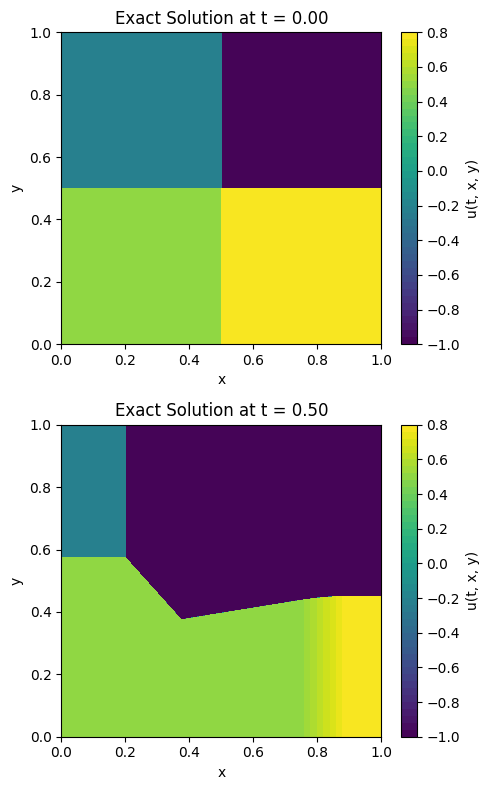

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [82]:
tl

Array([[[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [74]:
y_nodes

Array([[[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]]], dtype=float32)